# Early and Fair Dropout Prediction on OULAD
### A SHAP interaction-stability study of the first 28 days

**How to read this notebook.** Every section follows the same pattern: *code, output, interpretation*.
The interpretation lines are generated from the numbers, so they update if the data changes.

| Section | Content | Objective |
|---|---|---|
| 1 | Load data, build early-window features, define the day-28 risk set | data |
| 2 | EDA (class balance) | data |
| 3 | Train/test split by student, feature selection | data |
| 4 | Three models, six metrics each, comparison and ranking | **O1** |
| 5 | First-order SHAP | **O2** |
| 6 | SHAP interaction values and added value | **O3** |
| 7 | Stability of interactions: seeds, presentations, cut-offs, time | **O4** |
| 8 | Fairness by gender, age and IMD | **O5** |
| 9 | Sensitivity: why AUC here is lower than in many papers | method check |
| 10 | Objective checklist | summary |

**Design rules that fix the problems of the earlier version**
1. Only students *still registered at day 28* are scored (an early warning must warn about students who are still here).
2. Target = Withdrawn (1) versus Pass, Distinction **and Fail** (0).
3. Features are built per student **and** per course presentation, using only data up to the cut-off day.
4. Splits are grouped by `id_student`; imbalance is handled inside the training folds only.
5. Gender and age are **audit-only** attributes, not model inputs.

In [2]:
# ============================ 0. SETTINGS (everything adjustable lives here) ============================
import os, itertools, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

DATA_DIR = Path(os.environ.get("SDP_DATA_DIR", "data"))    # folder with the OULAD csv files
OUT_DIR  = Path("outputs"); (OUT_DIR / "figures").mkdir(parents=True, exist_ok=True)
(OUT_DIR / "tables").mkdir(parents=True, exist_ok=True); (OUT_DIR / "cache").mkdir(parents=True, exist_ok=True)

CUTOFFS      = [7, 14, 28]   # prediction windows (days since course start); the last one is the main one
MAIN_CUTOFF  = 28
SEED         = 42            # master random seed
N_FOLDS      = 5             # grouped cross-validation folds
TEST_SIZE    = 0.20          # share of students held out for testing
N_BOOT       = 500           # bootstrap repeats (students are resampled, not rows)
CORR_LIMIT   = 0.90          # drop one feature of a pair if |Spearman| is above this
TOP_K        = 10            # number of top interaction pairs compared in the stability study
SHAP_ROWS    = 2000          # test students used for SHAP / interaction values
STAB_ROWS    = 500           # students per run in the stability study
N_SEEDS      = 10            # repeated runs for seed stability
MIN_PRES_ROWS= 300           # smallest course presentation used in leave-one-presentation-out
CORE_SHARE   = 0.80          # a pair is 'core' if it is in the top-K in at least this share of runs (method choice)
MIN_POS      = 30            # groups with fewer dropouts than this are flagged as unreliable in fairness tables
IMD_GROUPS   = {"Most deprived (0-30%)": ["0-10%", "10-20%", "20-30%"],
                "Middle (30-70%)": ["30-40%", "40-50%", "50-60%", "60-70%"],
                "Least deprived (70-100%)": ["70-80%", "80-90%", "90-100%"]}   # grouping method choice, stated in the report

LGB_PARAMS = dict(n_estimators=300, learning_rate=0.03, num_leaves=15, max_depth=4, min_child_samples=40,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=5.0)
RF_PARAMS  = dict(n_estimators=300, max_depth=8, min_samples_leaf=20, class_weight="balanced_subsample")

def say(text):
    print("\nInterpretation: " + text)

def save_table(df, name):
    df.to_csv(OUT_DIR / "tables" / f"{name}.csv")

def save_fig(name):
    plt.savefig(OUT_DIR / "figures" / f"{name}.png", dpi=150, bbox_inches="tight")

print("Data folder:", DATA_DIR.resolve(), "| files found:", sorted(p.name for p in DATA_DIR.glob("*.csv")))

Data folder: C:\Users\ADMIN\Desktop\projects\DropAlert_Final\DropAlert\data | files found: ['assessments.csv', 'courses.csv', 'studentAssessment.csv', 'studentInfo.csv', 'studentRegistration.csv', 'vle.csv']


## 1. Data loading and early-window features
Six OULAD tables are used. From the click table (`studentVle`, ~10.6 million rows) only the first 28 days are kept, and
the clicks are summed **per student, course module and presentation** (a student who takes two courses gets two rows).
Features are built for three cut-offs (7, 14, 28 days) so that the study can also show *how early* a warning is possible.
The result is cached, so the large click file is only read once.

In [3]:
# ---------- helpers: building features for one cut-off day ----------
KEYS = ["id_student", "code_module", "code_presentation"]
EDU_ORDER = ["No Formal quals", "Lower Than A Level", "A Level or Equivalent", "HE Qualification", "Post Graduate Qualification"]

def read_clicks(max_day):
    parts = []
    for chunk in pd.read_csv(DATA_DIR / "studentVle.csv", chunksize=2_000_000):
        parts.append(chunk[chunk["date"] <= max_day])
    clicks = pd.concat(parts, ignore_index=True)
    site_type = pd.read_csv(DATA_DIR / "vle.csv").set_index("id_site")["activity_type"]
    clicks["activity_type"] = clicks["id_site"].map(site_type)
    return clicks

def build_cutoff(cutoff, base, clicks, subs):
    inwin = clicks[(clicks["date"] >= 0) & (clicks["date"] <= cutoff)]              # days 0..cutoff
    f = inwin.groupby(KEYS).agg(clicks_total=("sum_click", "sum"), active_days=("date", "nunique"),
                                first_day=("date", "min"), last_day=("date", "max"))
    f["clicks_prestart"] = clicks[(clicks["date"] < 0)].groupby(KEYS)["sum_click"].sum()    # before day 0 (available at the cut-off)
    late = inwin["date"] > cutoff / 2
    half = inwin.assign(late=late).groupby(KEYS + ["late"])["sum_click"].sum().unstack(fill_value=0)
    f["click_trend"] = half.get(True, 0) - half.get(False, 0)                       # second half minus first half of the window
    f["clicks_forum"] = inwin[inwin["activity_type"] == "forumng"].groupby(KEYS)["sum_click"].sum()
    f["n_submitted"] = subs[subs["date_submitted"] <= cutoff].groupby(KEYS).size()  # assessments submitted by the cut-off
    f = f.reset_index()
    out = base.merge(f, on=KEYS, how="left")
    for c in ["clicks_total", "active_days", "clicks_prestart", "click_trend", "clicks_forum", "n_submitted"]:
        out[c] = out[c].fillna(0)
    out["first_access_day"] = out["first_day"].fillna(cutoff + 1)                   # no click = 'after the window'
    out["days_since_last_access"] = (cutoff - out["last_day"]).fillna(cutoff + 1)
    out = out.drop(columns=["first_day", "last_day"])
    out["cutoff"] = cutoff
    return out

def build_features():
    info = pd.read_csv(DATA_DIR / "studentInfo.csv")
    reg = pd.read_csv(DATA_DIR / "studentRegistration.csv", na_values=["?"])
    asm = pd.read_csv(DATA_DIR / "assessments.csv", na_values=["?"])
    sa = pd.read_csv(DATA_DIR / "studentAssessment.csv", na_values=["?"])
    subs = sa.merge(asm[["id_assessment", "code_module", "code_presentation"]], on="id_assessment")
    base = info.merge(reg[KEYS + ["date_registration", "date_unregistration"]], on=KEYS, how="left")
    # ordinal codes
    base["imd_band"] = base["imd_band"].replace({"?": np.nan, "10-20": "10-20%"})
    imd_levels = sorted(base["imd_band"].dropna().unique(), key=lambda s: int(s.split("-")[0]))
    base["imd_ord"] = base["imd_band"].map({b: i for i, b in enumerate(imd_levels)})
    base["edu_ord"] = base["highest_education"].map({e: i for i, e in enumerate(EDU_ORDER)})
    base["disability_bin"] = (base["disability"] == "Y").astype(int)
    clicks = read_clicks(max(CUTOFFS))
    legacy = clicks[clicks["date"] <= MAIN_CUTOFF].groupby(KEYS).agg(legacy_total_clicks=("sum_click", "sum"),
             legacy_active_days=("date", "nunique"), legacy_n_types=("activity_type", "nunique")).reset_index()
    frames = [build_cutoff(c, base, clicks, subs) for c in CUTOFFS]
    frames[CUTOFFS.index(MAIN_CUTOFF)] = frames[CUTOFFS.index(MAIN_CUTOFF)].merge(legacy, on=KEYS, how="left")
    return pd.concat(frames, ignore_index=True), len(clicks)

CACHE = OUT_DIR / "cache" / "features_by_cutoff.csv"
if CACHE.exists():
    feat = pd.read_csv(CACHE)
    print("Loaded cached features:", CACHE)
else:
    feat, n_click_rows = build_features()
    feat.to_csv(CACHE, index=False)
    print(f"Built features from the raw click file ({n_click_rows:,} click rows inside the largest window). Saved to {CACHE}")
print("Feature table (all enrolments x cut-offs):", feat.shape)

Loaded cached features: outputs\cache\features_by_cutoff.csv
Feature table (all enrolments x cut-offs): (97779, 29)


In [4]:
# ---------- shape of the data and the day-28 risk set ----------
feat_main = feat[feat["cutoff"] == MAIN_CUTOFF].copy()
n_all = len(feat_main)
n_unreg_before = int((feat_main["date_unregistration"] <= MAIN_CUTOFF).sum())
n_reg_after = int((feat_main["date_registration"] > MAIN_CUTOFF).sum())
at_risk = (feat_main["date_unregistration"].isna() | (feat_main["date_unregistration"] > MAIN_CUTOFF)) & \
          (feat_main["date_registration"].isna() | (feat_main["date_registration"] <= MAIN_CUTOFF))
funnel = pd.DataFrame({"Step": ["All course enrolments (student x presentation)",
                                f"Left (unregistered) on or before day {MAIN_CUTOFF}",
                                f"Registered only after day {MAIN_CUTOFF}",
                                f"Risk set: still registered at day {MAIN_CUTOFF}"],
                       "Students": [n_all, n_unreg_before, n_reg_after, int(at_risk.sum())]})
display(funnel)
withdrawn_all = feat_main["final_result"].eq("Withdrawn")
say(f"{n_unreg_before:,} enrolments ({n_unreg_before / n_all:.1%}) had already left by day {MAIN_CUTOFF}; they are not scored, "
    f"because predicting them would be a registration lookup, not an early warning. "
    f"They account for {int((withdrawn_all & (feat_main['date_unregistration'] <= MAIN_CUTOFF)).sum()):,} of the "
    f"{int(withdrawn_all.sum()):,} Withdrawn outcomes ({(withdrawn_all & (feat_main['date_unregistration'] <= MAIN_CUTOFF)).sum() / withdrawn_all.sum():.1%}).")

,Step,Students
0,All course enrolments (student x presentation),32593
1,Left (unregistered) on or before day 28,5055
2,Registered only after day 28,16
3,Risk set: still registered at day 28,27522



Interpretation: 5,055 enrolments (15.5%) had already left by day 28; they are not scored, because predicting them would be a registration lookup, not an early warning. They account for 5,047 of the 10,156 Withdrawn outcomes (49.7%).


## 2. Exploratory data analysis (before any resampling or weighting)

Risk set: (27522, 33) | distinct students: 24832 | students with more than one row: 2571


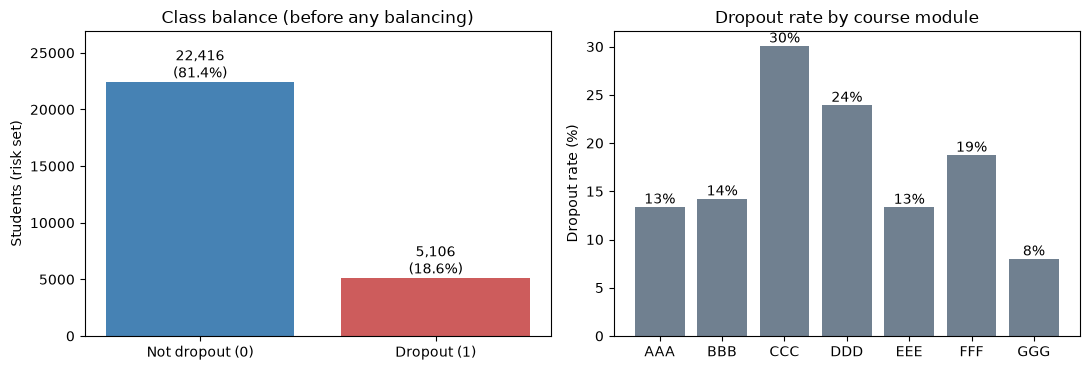


Interpretation: Dropout is the minority class (18.6%, imbalance 4.4 : 1). Accuracy alone would therefore be misleading, so recall, F1 and PR-AUC are reported too. Dropout also differs strongly between modules (8% to 30%), so the module is kept as an input.


In [5]:
# ---------- risk-set table used from here on ----------
def make_cohort(frame, cutoff, drop_fail=False):
    d = frame[frame["cutoff"] == cutoff].copy()
    keep = (d["date_unregistration"].isna() | (d["date_unregistration"] > cutoff)) & \
           (d["date_registration"].isna() | (d["date_registration"] <= cutoff))
    d = d[keep]
    if drop_fail:
        d = d[d["final_result"] != "Fail"]
    d["y"] = (d["final_result"] == "Withdrawn").astype(int)       # 1 = Withdrawn ; 0 = Pass, Distinction, Fail
    d["pres"] = d["code_module"] + "-" + d["code_presentation"]
    d["year"] = d["code_presentation"].str[:4]
    imd_group = {b: g for g, bands in IMD_GROUPS.items() for b in bands}
    d["imd_group"] = d["imd_band"].map(imd_group).fillna("Unknown")
    return d.reset_index(drop=True)

df = make_cohort(feat, MAIN_CUTOFF)
print("Risk set:", df.shape, "| distinct students:", df["id_student"].nunique(),
      "| students with more than one row:", int((df["id_student"].value_counts() > 1).sum()))

counts = df["y"].value_counts().sort_index()
by_mod = df.groupby("code_module")["y"].agg(["mean", "size"])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
bars = ax[0].bar(["Not dropout (0)", "Dropout (1)"], counts.values, color=["steelblue", "indianred"])
ax[0].bar_label(bars, labels=[f"{n:,}\n({n / counts.sum():.1%})" for n in counts.values])
ax[0].set_ylim(0, counts.max() * 1.2); ax[0].set_ylabel("Students (risk set)"); ax[0].set_title("Class balance (before any balancing)")
bars = ax[1].bar(by_mod.index, by_mod["mean"] * 100, color="slategray")
ax[1].bar_label(bars, fmt="%.0f%%"); ax[1].set_ylabel("Dropout rate (%)"); ax[1].set_title("Dropout rate by course module")
plt.tight_layout(); save_fig("fig1_eda_class_balance"); plt.show()
say(f"Dropout is the minority class ({counts[1] / counts.sum():.1%}, imbalance {counts[0] / counts[1]:.1f} : 1). Accuracy alone would "
    f"therefore be misleading, so recall, F1 and PR-AUC are reported too. Dropout also differs strongly between modules "
    f"({by_mod['mean'].min():.0%} to {by_mod['mean'].max():.0%}), so the module is kept as an input.")

## 3. Train/test split and feature selection
Students (not rows) are split 80/20, because a student who took two courses must never appear on both sides.

In [6]:
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
from scipy import stats
from sklearn.metrics import roc_auc_score

NUMERIC = ["clicks_total", "active_days", "clicks_prestart", "first_access_day", "days_since_last_access", "click_trend",
           "clicks_forum", "n_submitted", "date_registration", "num_of_prev_attempts", "studied_credits", "edu_ord", "imd_ord", "disability_bin"]
MODULES = sorted(df["code_module"].unique())

def make_X(frame, cols=None):
    X = frame[NUMERIC].copy()
    for m in MODULES:
        X["module_" + m] = (frame["code_module"] == m).astype(int)
    return X if cols is None else X[cols]

def var_of(col):
    return "code_module" if col.startswith("module_") else col

tr_pos, te_pos = next(GroupShuffleSplit(1, test_size=TEST_SIZE, random_state=SEED).split(df, df["y"], groups=df["id_student"]))
train, test = df.iloc[tr_pos].reset_index(drop=True), df.iloc[te_pos].reset_index(drop=True)
print(f"Train: {len(train):,} rows ({train['y'].mean():.1%} dropout) | Test: {len(test):,} rows ({test['y'].mean():.1%} dropout) | "
      f"students shared between train and test: {len(set(train['id_student']) & set(test['id_student']))}")

# ---- feature pruning, using the TRAINING students only ----
X_all_train = make_X(train)
eng = ["clicks_total", "active_days", "clicks_prestart", "first_access_day", "days_since_last_access", "click_trend", "clicks_forum", "n_submitted"]
rho = X_all_train[eng].corr(method="spearman").abs()
dropped = []
for a, b in itertools.combinations(eng, 2):
    if a in dropped or b in dropped:
        continue
    if rho.loc[a, b] > CORR_LIMIT:
        auc_a = abs(roc_auc_score(train["y"], X_all_train[a]) - 0.5); auc_b = abs(roc_auc_score(train["y"], X_all_train[b]) - 0.5)
        dropped.append(b if auc_a >= auc_b else a)
        print(f"  |Spearman| {a} vs {b} = {rho.loc[a, b]:.2f} > {CORR_LIMIT}: dropping {dropped[-1]} (weaker single-feature AUC)")
FEATURES = [c for c in X_all_train.columns if c not in dropped]
X_train, X_test = make_X(train, FEATURES), make_X(test, FEATURES)
y_train, y_test = train["y"], test["y"]
g_train, g_test = train["id_student"], test["id_student"]
VARIABLES = list(dict.fromkeys(var_of(c) for c in FEATURES))
print("\nModel inputs:", len(FEATURES), "columns =", len(VARIABLES), "variables:", VARIABLES)
print("Audit-only (not model inputs): gender, age_band ; IMD is an input and is also audited.")
display(rho.round(2))
say(f"Spearman correlation between engagement features shows which ones carry the same information. "
    f"{'Dropped to avoid unstable SHAP credit sharing: ' + ', '.join(dropped) if dropped else 'No pair exceeded the limit.'} "
    f"The test set holds {test['id_student'].nunique():,} students who never appear in training.")

Train: 22,010 rows (18.4% dropout) | Test: 5,512 rows (19.2% dropout) | students shared between train and test: 0

Model inputs: 21 columns = 15 variables: ['clicks_total', 'active_days', 'clicks_prestart', 'first_access_day', 'days_since_last_access', 'click_trend', 'clicks_forum', 'n_submitted', 'date_registration', 'num_of_prev_attempts', 'studied_credits', 'edu_ord', 'imd_ord', 'disability_bin', 'code_module']
Audit-only (not model inputs): gender, age_band ; IMD is an input and is also audited.


,clicks_total,active_days,clicks_prestart,first_access_day,days_since_last_access,click_trend,clicks_forum,n_submitted
clicks_total,1.00,0.87,0.58,0.55,0.63,0.03,0.80,0.41
active_days,0.87,1.00,0.62,0.64,0.71,0.08,0.78,0.42
clicks_prestart,0.58,0.62,1.00,0.50,0.43,0.12,0.54,0.33
first_access_day,0.55,0.64,0.50,1.00,0.41,0.19,0.50,0.27
days_since_last_access,0.63,0.71,0.43,0.41,1.00,0.08,0.54,0.34
click_trend,0.03,0.08,0.12,0.19,0.08,1.00,0.12,0.02
clicks_forum,0.80,0.78,0.54,0.50,0.54,0.12,1.00,0.38
n_submitted,0.41,0.42,0.33,0.27,0.34,0.02,0.38,1.00



Interpretation: Spearman correlation between engagement features shows which ones carry the same information. No pair exceeded the limit. The test set holds 4,967 students who never appear in training.


## 4. Objective 1 - Build and compare early-warning models
**Models:** Logistic Regression and Random Forest (baselines), LightGBM (primary).
**Imbalance:** handled with class weights *inside* each model (no synthetic students, nothing leaks into the test set).
**Evaluation:** Accuracy, Precision, Recall, F1, ROC-AUC, PR-AUC, plus calibration (Brier score, ECE).
**Procedure for every model:** (1) 5-fold cross-validation grouped by student on the training set gives out-of-fold predictions;
(2) a Platt calibrator and the decision threshold (best F1) are learned **from those out-of-fold predictions only**;
(3) the model is refitted on the full training set and judged once on the untouched test set.

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score,
                             brier_score_loss, roc_curve, precision_recall_curve, confusion_matrix)
from lightgbm import LGBMClassifier
import shap

METRICS = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]
MODEL_NAMES = ["Logistic Regression", "Random Forest", "LightGBM"]

def signed_log1p(x):
    return np.sign(x) * np.log1p(np.abs(x))          # tames very large click counts for the linear model

def make_model(name, seed, spw, **over):
    if name == "Logistic Regression":
        return make_pipeline(SimpleImputer(strategy="median"), FunctionTransformer(signed_log1p), StandardScaler(),
                             LogisticRegression(max_iter=2000, class_weight="balanced"))
    if name == "Random Forest":
        return make_pipeline(SimpleImputer(strategy="median"),
                             RandomForestClassifier(**{**RF_PARAMS, **over}, n_jobs=-1, random_state=seed))
    params = {**LGB_PARAMS, **over}                  # LightGBM (also used with overrides for the additive model)
    return LGBMClassifier(**params, scale_pos_weight=spw, random_state=seed, verbose=-1, n_jobs=-1)

def spw_of(y):
    return (y == 0).sum() / max((y == 1).sum(), 1)

def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)

class Platt:                                          # monotone probability calibration (does not change ROC-AUC)
    def fit(self, p, y):
        self.m = LogisticRegression(C=1e6).fit(logit(p), y); return self
    def transform(self, p):
        return self.m.predict_proba(logit(p))[:, 1]

def best_f1_threshold(y, p):
    pr, rc, th = precision_recall_curve(y, p)
    return th[np.argmax((2 * pr * rc / (pr + rc + 1e-12))[:-1])]

def six_metrics(y, p, thr):
    pred = (p >= thr).astype(int)
    return {"Accuracy": accuracy_score(y, pred), "Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred), "F1": f1_score(y, pred),
            "ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p)}

def ece_score(y, p, bins=10):
    edges = np.linspace(0, 1, bins + 1); idx = np.clip(np.digitize(p, edges) - 1, 0, bins - 1); e = 0.0
    for b in range(bins):
        m = idx == b
        if m.any():
            e += m.mean() * abs(np.mean(y[m]) - np.mean(p[m]))
    return e

cv = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
FOLDS = list(cv.split(X_train, y_train, groups=g_train))

def get_oof(name, cols=None, **over):
    Xt = X_train if cols is None else X_train[cols]
    oof = np.zeros(len(Xt))
    for tr, va in FOLDS:
        m = make_model(name, SEED, spw_of(y_train.iloc[tr]), **over).fit(Xt.iloc[tr], y_train.iloc[tr])
        oof[va] = m.predict_proba(Xt.iloc[va])[:, 1]
    return oof

class StudentBoot:
    # bootstrap that resamples whole students, because one student can have several rows
    def __init__(self, groups, n_boot=N_BOOT, seed=SEED):
        codes, uniq = pd.factorize(np.asarray(groups))
        order = np.argsort(codes, kind="stable"); bounds = np.r_[0, np.cumsum(np.bincount(codes))]
        rows = [order[bounds[k]:bounds[k + 1]] for k in range(len(uniq))]
        rng = np.random.default_rng(seed)
        self.draws = [np.concatenate([rows[k] for k in rng.integers(0, len(uniq), len(uniq))]) for _ in range(n_boot)]
    def values(self, fn):
        out = []
        for idx in self.draws:
            try: out.append(fn(idx))
            except Exception: out.append(np.nan)
        return np.array(out, dtype=float)

def ci(vals, level=95):
    lo, hi = np.nanpercentile(vals, [(100 - level) / 2, 100 - (100 - level) / 2]); return lo, hi

boot_test = StudentBoot(g_test)
RESULTS = {}

def run_model(name):
    oof_raw = get_oof(name)
    platt = Platt().fit(oof_raw, y_train.values)
    oof = platt.transform(oof_raw)
    thr = best_f1_threshold(y_train.values, oof)
    final = make_model(name, SEED, spw_of(y_train)).fit(X_train, y_train)
    p_test = platt.transform(final.predict_proba(X_test)[:, 1])
    cv_rows = [six_metrics(y_train.iloc[va].values, oof[va], thr) for _, va in FOLDS]
    RESULTS[name] = dict(model=final, platt=platt, thr=thr, oof_raw=oof_raw, oof=oof, p_test=p_test,
                         test=six_metrics(y_test.values, p_test, thr), cv=pd.DataFrame(cv_rows),
                         brier=brier_score_loss(y_test, p_test), ece=ece_score(y_test.values, p_test))
    r = RESULTS[name]
    print(f"{name}: decision threshold (from out-of-fold training predictions) = {thr:.3f}")
    print("Cross-validation (mean +/- SD over folds):")
    print((r['cv'].mean().round(3).astype(str) + " +/- " + r['cv'].std().round(3).astype(str)).to_string())
    print("Test set:"); print(pd.Series(r["test"]).round(3).to_string())
    print(f"Calibration on test: Brier = {r['brier']:.3f}, ECE = {r['ece']:.3f}")

#### Model 1 - Logistic Regression (baseline)

In [8]:
run_model('Logistic Regression')

Logistic Regression: decision threshold (from out-of-fold training predictions) = 0.192
Cross-validation (mean +/- SD over folds):
Accuracy     0.667 +/- 0.007
Precision    0.297 +/- 0.007
Recall        0.59 +/- 0.007
F1           0.395 +/- 0.007
ROC-AUC      0.682 +/- 0.005
PR-AUC       0.329 +/- 0.008
Test set:
Accuracy     0.669
Precision    0.313
Recall       0.608
F1           0.414
ROC-AUC      0.694
PR-AUC       0.353
Calibration on test: Brier = 0.143, ECE = 0.013


#### Model 2 - Random Forest (baseline)

In [9]:
run_model('Random Forest')

Random Forest: decision threshold (from out-of-fold training predictions) = 0.179
Cross-validation (mean +/- SD over folds):
Accuracy     0.627 +/- 0.005
Precision    0.277 +/- 0.002
Recall        0.64 +/- 0.008
F1           0.387 +/- 0.002
ROC-AUC      0.679 +/- 0.005
PR-AUC        0.333 +/- 0.01
Test set:
Accuracy     0.636
Precision    0.298
Recall       0.662
F1           0.411
ROC-AUC      0.698
PR-AUC       0.371
Calibration on test: Brier = 0.142, ECE = 0.010


#### Model 3 - LightGBM (primary model)

In [10]:
run_model('LightGBM')

LightGBM: decision threshold (from out-of-fold training predictions) = 0.203
Cross-validation (mean +/- SD over folds):
Accuracy     0.683 +/- 0.006
Precision    0.304 +/- 0.006
Recall       0.564 +/- 0.013
F1           0.395 +/- 0.007
ROC-AUC      0.686 +/- 0.006
PR-AUC       0.347 +/- 0.009
Test set:
Accuracy     0.686
Precision    0.323
Recall       0.580
F1           0.415
ROC-AUC      0.705
PR-AUC       0.380
Calibration on test: Brier = 0.141, ECE = 0.009


### O1 results: Table 1 (test metrics with 95% intervals), Table 2 (confusion counts), ranking, curves

In [11]:
# ---------- Table 1: six metrics on the test set, with student-level bootstrap intervals ----------
def metric_fn(name, metric):
    p, thr = RESULTS[name]["p_test"], RESULTS[name]["thr"]
    yv = y_test.values
    def f(idx):
        return six_metrics(yv[idx], p[idx], thr)[metric]
    return f

rows = []
for n in MODEL_NAMES:
    row = {"Model": n}
    for m in METRICS:
        lo, hi = ci(boot_test.values(metric_fn(n, m)))
        row[m] = f"{RESULTS[n]['test'][m]:.3f} [{lo:.3f}, {hi:.3f}]"
    rows.append(row)
table1 = pd.DataFrame(rows).set_index("Model"); display(table1); save_table(table1, "table1_test_metrics_ci")

# ---------- Table 2: confusion counts ----------
rows = []
for n in MODEL_NAMES:
    tn, fp, fn, tp = confusion_matrix(y_test, (RESULTS[n]["p_test"] >= RESULTS[n]["thr"]).astype(int)).ravel()
    rows.append({"Model": n, "True neg": tn, "False pos": fp, "False neg": fn, "True pos": tp})
table2 = pd.DataFrame(rows).set_index("Model"); display(table2); save_table(table2, "table2_confusion")

# ---------- Table 3: ranking (mean rank over the six metrics; 1 = best) ----------
vals = pd.DataFrame({n: RESULTS[n]["test"] for n in MODEL_NAMES}).T[METRICS]
ranks = vals.rank(ascending=False, method="min")
ranking = pd.DataFrame({"Mean rank": ranks.mean(axis=1)}).join(vals[["ROC-AUC", "PR-AUC"]])
ranking["Final rank"] = ranking["Mean rank"].rank(method="min").astype(int)
ranking = ranking.sort_values("Final rank"); display(ranking.round(3)); save_table(ranking, "table3_ranking")

# ---------- are the AUC differences real? paired student bootstrap ----------
pt = {n: RESULTS[n]["p_test"] for n in MODEL_NAMES}; yv = y_test.values
paired = []
for a, b in [("LightGBM", "Logistic Regression"), ("LightGBM", "Random Forest"), ("Random Forest", "Logistic Regression")]:
    d = boot_test.values(lambda idx: roc_auc_score(yv[idx], pt[a][idx]) - roc_auc_score(yv[idx], pt[b][idx]))
    lo, hi = ci(d); paired.append({"Comparison": f"{a} - {b}", "Delta ROC-AUC": roc_auc_score(yv, pt[a]) - roc_auc_score(yv, pt[b]),
                                   "95% CI": f"[{lo:.3f}, {hi:.3f}]", "Clear difference?": "Yes" if (lo > 0 or hi < 0) else "No"})
paired = pd.DataFrame(paired).set_index("Comparison"); display(paired.round(3)); save_table(paired, "table3b_paired_auc")

best = ranking.index[0]
auc_txt = ", ".join(n + " " + format(RESULTS[n]["test"]["ROC-AUC"], ".3f") for n in MODEL_NAMES)
say(f"{best} ranks first on the average of the six metrics, but ROC-AUC is the fairest single summary: "
    f"{auc_txt}. "
    f"Pairs whose AUC interval excludes zero are really different; the others are statistical ties. "
    f"AUC around 0.6-0.75 is expected at day {MAIN_CUTOFF}: students who are still registered and active look alike this early, "
    f"so this is a harder (and more honest) task than predicting everyone, including students who already left.")

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,,
Logistic Regression,"0.669 [0.658, 0.681]","0.313 [0.295, 0.333]","0.608 [0.578, 0.635]","0.414 [0.392, 0.433]","0.694 [0.677, 0.710]","0.353 [0.326, 0.383]"
Random Forest,"0.636 [0.624, 0.648]","0.298 [0.280, 0.316]","0.662 [0.634, 0.689]","0.411 [0.391, 0.432]","0.698 [0.681, 0.714]","0.371 [0.342, 0.404]"
LightGBM,"0.686 [0.674, 0.698]","0.323 [0.302, 0.344]","0.580 [0.547, 0.609]","0.415 [0.394, 0.437]","0.705 [0.688, 0.722]","0.380 [0.351, 0.414]"


,True neg,False pos,False neg,True pos
Model,,,,
Logistic Regression,3045,1410,414,643
Random Forest,2805,1650,357,700
LightGBM,3168,1287,444,613


,Mean rank,ROC-AUC,PR-AUC,Final rank
LightGBM,1.333,0.705,0.380,1
Logistic Regression,2.333,0.694,0.353,2
Random Forest,2.333,0.698,0.371,2


,Delta ROC-AUC,95% CI,Clear difference?
Comparison,,,
LightGBM - Logistic Regression,0.011,"[0.003, 0.019]",Yes
LightGBM - Random Forest,0.007,"[0.001, 0.013]",Yes
Random Forest - Logistic Regression,0.004,"[-0.004, 0.012]",No



Interpretation: LightGBM ranks first on the average of the six metrics, but ROC-AUC is the fairest single summary: Logistic Regression 0.694, Random Forest 0.698, LightGBM 0.705. Pairs whose AUC interval excludes zero are really different; the others are statistical ties. AUC around 0.6-0.75 is expected at day 28: students who are still registered and active look alike this early, so this is a harder (and more honest) task than predicting everyone, including students who already left.


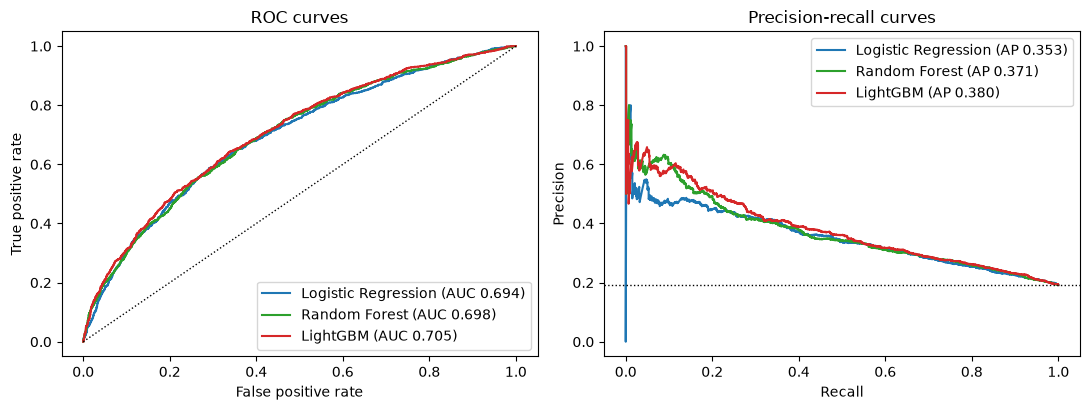

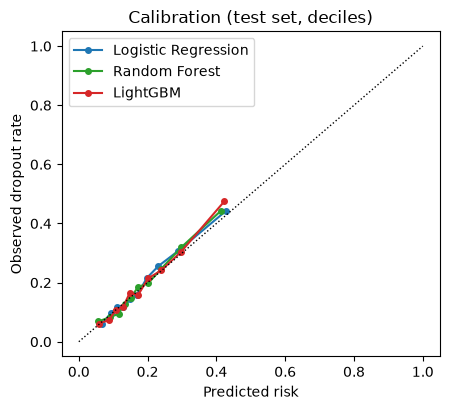


Interpretation: Points close to the dotted line mean that a predicted risk of, say, 30% really corresponds to about 30% of those students dropping out. After Platt calibration the Brier scores are Logistic Regression 0.143, Random Forest 0.142, LightGBM 0.141 and ECE 0.013, 0.010, 0.009 (lower is better).


In [12]:
# ---------- Figure 2: ROC and precision-recall curves ----------
colors = {"Logistic Regression": "tab:blue", "Random Forest": "tab:green", "LightGBM": "tab:red"}
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for n in MODEL_NAMES:
    fpr, tpr, _ = roc_curve(y_test, RESULTS[n]["p_test"]); ax[0].plot(fpr, tpr, color=colors[n], label=f"{n} (AUC {RESULTS[n]['test']['ROC-AUC']:.3f})")
    pr, rc, _ = precision_recall_curve(y_test, RESULTS[n]["p_test"]); ax[1].plot(rc, pr, color=colors[n], label=f"{n} (AP {RESULTS[n]['test']['PR-AUC']:.3f})")
ax[0].plot([0, 1], [0, 1], "k:", lw=1); ax[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curves"); ax[0].legend(loc="lower right")
ax[1].axhline(y_test.mean(), color="k", ls=":", lw=1); ax[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall curves"); ax[1].legend(loc="upper right")
plt.tight_layout(); save_fig("fig2_roc_pr"); plt.show()

# ---------- Figure 3: calibration of the primary model ----------
fig, ax = plt.subplots(figsize=(4.6, 4.2))
for n in MODEL_NAMES:
    edges = np.quantile(RESULTS[n]["p_test"], np.linspace(0, 1, 11)); idx = np.clip(np.digitize(RESULTS[n]["p_test"], edges[1:-1]), 0, 9)
    ax.plot([RESULTS[n]["p_test"][idx == b].mean() for b in range(10)], [y_test.values[idx == b].mean() for b in range(10)], "o-", color=colors[n], label=n, ms=4)
ax.plot([0, 1], [0, 1], "k:", lw=1); ax.set(xlabel="Predicted risk", ylabel="Observed dropout rate", title="Calibration (test set, deciles)"); ax.legend()
plt.tight_layout(); save_fig("fig3_calibration"); plt.show()
brier_txt = ", ".join(n + " " + format(RESULTS[n]["brier"], ".3f") for n in MODEL_NAMES)
ece_txt = ", ".join(format(RESULTS[n]["ece"], ".3f") for n in MODEL_NAMES)
say(f"Points close to the dotted line mean that a predicted risk of, say, 30% really corresponds to about 30% of those students dropping out. "
    f"After Platt calibration the Brier scores are {brier_txt} and ECE {ece_txt} (lower is better).")

## 5. Objective 2 - Key single predictors (first-order SHAP)
SHAP values are computed with `TreeExplainer` for the primary model (LightGBM) on the **test students**, who were never used for training.
A SHAP value is how much a feature pushes one student's predicted dropout risk up (+) or down (-), in log-odds.
Module dummy columns are added together so that every original variable has one importance.

In [13]:
lgb_final = RESULTS["LightGBM"]["model"]
explainer = shap.TreeExplainer(lgb_final)

def shap_pos(values):
    # different SHAP versions return different shapes; keep the 'dropout = 1' values: (rows, features)
    if isinstance(values, list):
        values = values[1]
    values = np.asarray(values)
    return values[..., 1] if values.ndim == 3 else values

rng = np.random.default_rng(SEED)
shap_idx = np.sort(rng.choice(len(X_test), size=min(SHAP_ROWS, len(X_test)), replace=False))   # same students are reused for O3 and O5
Xs, ys, ts = X_test.iloc[shap_idx], y_test.iloc[shap_idx], test.iloc[shap_idx]
sv = shap_pos(explainer.shap_values(Xs))
print("SHAP matrix (students, features):", sv.shape)

# --- one importance per original variable ---
sv_df = pd.DataFrame(sv, columns=Xs.columns)
sv_var = sv_df.T.groupby([var_of(c) for c in Xs.columns]).sum().T
boot_s = StudentBoot(ts["id_student"].values)
imp = sv_var.abs().mean()
imp_ci = np.array([sv_var.abs().values[idx].mean(axis=0) for idx in boot_s.draws])
table4 = pd.DataFrame({"Mean |SHAP|": imp, "CI low": np.percentile(imp_ci, 2.5, axis=0), "CI high": np.percentile(imp_ci, 97.5, axis=0)})
table4["Share of total"] = table4["Mean |SHAP|"] / table4["Mean |SHAP|"].sum()
# direction: Spearman correlation between the feature value and its SHAP value (single-column variables only)
def direction(var):
    cols = [c for c in Xs.columns if var_of(c) == var]
    if len(cols) > 1:
        return "categorical"
    r = stats.spearmanr(Xs[cols[0]], sv_var[var])[0]
    return "higher value -> higher risk" if r > 0.1 else ("higher value -> lower risk" if r < -0.1 else "mixed")
table4["Direction"] = [direction(v) for v in table4.index]
table4["Rho (value vs SHAP)"] = [stats.spearmanr(Xs[v], sv_var[v])[0] if v in Xs.columns else np.nan for v in table4.index]
table4 = table4.sort_values("Mean |SHAP|", ascending=False); table4["Rank"] = np.arange(1, len(table4) + 1)
display(table4.round(3)); save_table(table4, "table4_shap_importance")
top3 = table4.head(3)
say(f"The three most influential variables are {', '.join(top3.index)}; together they carry {top3['Share of total'].sum():.0%} of all single-feature influence. "
    f"The intervals are 95% bootstrap intervals over students. Directions tell how a variable moves risk after the other variables are accounted for. "
    f"SHAP describes what the model uses, not what causes dropout.")

SHAP matrix (students, features): (2000, 21)


,Mean |SHAP|,CI low,CI high,Share of total,Direction,Rho (value vs SHAP),Rank
code_module,0.381,0.372,0.391,0.256,categorical,NaN,1
studied_credits,0.154,0.148,0.161,0.103,higher value -> higher risk,0.908,2
n_submitted,0.139,0.134,0.145,0.093,higher value -> lower risk,-0.870,3
edu_ord,0.126,0.124,0.128,0.084,higher value -> lower risk,-0.732,4
days_since_last_access,0.108,0.105,0.110,0.072,higher value -> higher risk,0.902,5
imd_ord,0.087,0.084,0.090,0.058,mixed,NaN,6
active_days,0.082,0.079,0.085,0.055,higher value -> lower risk,-0.888,7
clicks_prestart,0.072,0.069,0.074,0.048,higher value -> lower risk,-0.837,8
clicks_total,0.061,0.058,0.064,0.041,higher value -> lower risk,-0.820,9
date_registration,0.060,0.058,0.063,0.040,higher value -> lower risk,-0.860,10



Interpretation: The three most influential variables are code_module, studied_credits, n_submitted; together they carry 45% of all single-feature influence. The intervals are 95% bootstrap intervals over students. Directions tell how a variable moves risk after the other variables are accounted for. SHAP describes what the model uses, not what causes dropout.


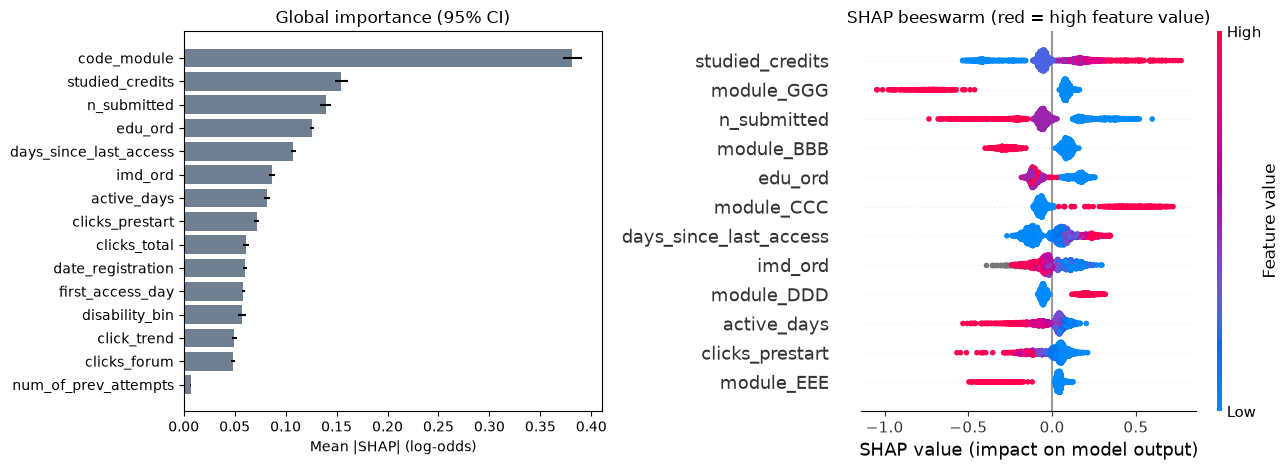

,Predicted risk,Actual dropout,"Top 3 reasons (SHAP, log-odds)"
Student,,,
Highest predicted risk,0.66,0,studied_credits (+0.70); code_module (+0.44); ...
Median predicted risk,0.16,0,code_module (+0.36); days_since_last_access (-...
Lowest predicted risk,0.02,0,n_submitted (-0.57); active_days (-0.51); clic...



Interpretation: The local table shows why individual students were flagged (or not). A positive number pushes this student's risk up. This is what an adviser would read before contacting a student.


In [14]:
# ---------- Figure 4: SHAP bar plot and beeswarm (variable level) ----------
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
order = table4.index[::-1]
ax[0].barh(order, table4.loc[order, "Mean |SHAP|"], xerr=[table4.loc[order, "Mean |SHAP|"] - table4.loc[order, "CI low"], table4.loc[order, "CI high"] - table4.loc[order, "Mean |SHAP|"]], color="slategray")
ax[0].set_xlabel("Mean |SHAP| (log-odds)"); ax[0].set_title("Global importance (95% CI)")
plt.sca(ax[1])
shap.summary_plot(sv, Xs, max_display=12, show=False, plot_size=None)
ax[1].set_title("SHAP beeswarm (red = high feature value)")
plt.tight_layout(); save_fig("fig4_shap_bar_beeswarm"); plt.show()

# ---------- local explanation: a high-risk, a middle and a low-risk student ----------
p_s = RESULTS["LightGBM"]["p_test"][shap_idx]
picks = {"Highest predicted risk": int(np.argmax(p_s)), "Median predicted risk": int(np.argsort(p_s)[len(p_s) // 2]), "Lowest predicted risk": int(np.argmin(p_s))}
rows = []
for label, i in picks.items():
    top = sv_var.iloc[i].reindex(sv_var.iloc[i].abs().sort_values(ascending=False).index)[:3]
    rows.append({"Student": label, "Predicted risk": f"{p_s[i]:.2f}", "Actual dropout": int(ys.iloc[i]),
                 "Top 3 reasons (SHAP, log-odds)": "; ".join(f"{k} ({v:+.2f})" for k, v in top.items())})
table5 = pd.DataFrame(rows).set_index("Student"); display(table5); save_table(table5, "table5_local_explanations")
say("The local table shows why individual students were flagged (or not). A positive number pushes this student's risk up. "
    "This is what an adviser would read before contacting a student.")

## 6. Objective 3 - Feature interactions (SHAP interaction values)
SHAP interaction values split each prediction into *main effects* (a variable alone) and *pair effects* (two variables together).
Interactions are measured **between original variables**: the module dummy columns are merged, so a variable is never paired with itself.
The "added value" test asks whether the pair effects improve prediction: the full LightGBM is compared with an **additive** LightGBM
(depth-1 trees cannot represent interactions; it gets 600 trees so it is not handicapped), using out-of-fold predictions on the training students.

In [15]:
iv = explainer.shap_interaction_values(Xs)
iv = np.asarray(iv[1] if isinstance(iv, list) else iv)
iv = iv[..., 1] if iv.ndim == 4 else iv
print("Interaction array (students, features, features):", iv.shape)

col_idx = {v: [i for i, c in enumerate(Xs.columns) if var_of(c) == v] for v in VARIABLES}

def pair_values(iv_arr, a, b):
    # per-student interaction effect between variables a and b (both directions together)
    return 2 * iv_arr[:, col_idx[a]][:, :, col_idx[b]].sum(axis=(1, 2))

def pair_strengths(iv_arr):
    return pd.Series({f"{a} x {b}": np.abs(pair_values(iv_arr, a, b)).mean() for a, b in itertools.combinations(VARIABLES, 2)})

S_main = pair_strengths(iv)
main_eff = pd.Series({v: np.abs(iv[:, col_idx[v]][:, :, col_idx[v]].sum(axis=(1, 2))).mean() for v in VARIABLES})
pair_total, main_total = S_main.sum(), main_eff.sum()
table6 = S_main.sort_values(ascending=False).head(TOP_K).to_frame("Interaction strength")
table6["Share of all pair effects"] = table6["Interaction strength"] / pair_total
table6["Rank"] = np.arange(1, len(table6) + 1); display(table6.round(4)); save_table(table6, "table6_top_interactions")

summary7 = pd.DataFrame({"Main effects (sum of variables)": [main_total], "Pair effects (sum of pairs)": [pair_total],
                         "Pair share of attribution": [pair_total / (main_total + pair_total)]}, index=["Mean |SHAP| units"])
display(summary7.round(3)); save_table(summary7, "table7_main_vs_interaction")
share_pairs = pair_total / (main_total + pair_total)
strong_mod = sum("code_module" in p for p in table6.index)
say(f"The strongest pairs are {', '.join(table6.index[:3])}. Pair effects make up {share_pairs:.1%} of the total attribution "
    f"({'single variables carry more' if share_pairs < 0.5 else 'pairs carry as much as single variables'}). "
    f"{strong_mod} of the top {TOP_K} pairs involve code_module: the course module changes how engagement and assessment variables are used, "
    f"partly because modules differ in assessment timing and design. How much this helps prediction is tested below.")

Interaction array (students, features, features): (2000, 21, 21)


,Interaction strength,Share of all pair effects,Rank
n_submitted x code_module,0.0867,0.0796,1
click_trend x code_module,0.0397,0.0364,2
studied_credits x code_module,0.0374,0.0344,3
clicks_prestart x days_since_last_access,0.0334,0.0307,4
days_since_last_access x code_module,0.0299,0.0274,5
n_submitted x studied_credits,0.0281,0.0258,6
date_registration x code_module,0.0274,0.0252,7
clicks_forum x code_module,0.0272,0.0249,8
clicks_total x clicks_forum,0.0219,0.0201,9
clicks_total x code_module,0.0210,0.0193,10


,Main effects (sum of variables),Pair effects (sum of pairs),Pair share of attribution
Mean |SHAP| units,1.437,1.09,0.431



Interpretation: The strongest pairs are n_submitted x code_module, click_trend x code_module, studied_credits x code_module. Pair effects make up 43.1% of the total attribution (single variables carry more). 7 of the top 10 pairs involve code_module: the course module changes how engagement and assessment variables are used, partly because modules differ in assessment timing and design. How much this helps prediction is tested below.


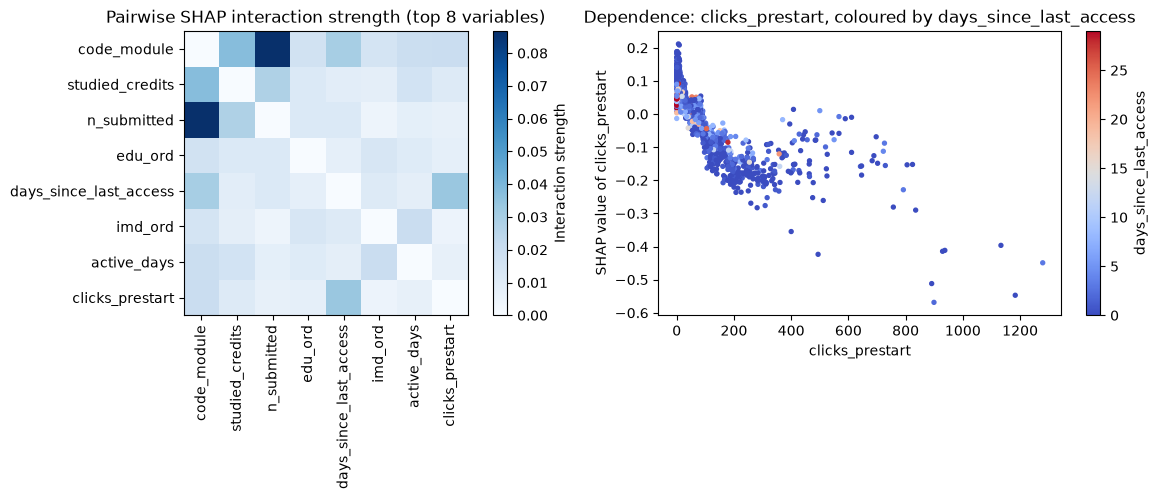


Interpretation: Dark cells in the heat map are variable pairs that act together. In the dependence plot, if points at the same x-value have different heights that line up with the colour, the effect of the x variable depends on the colour variable - that is an interaction.


In [16]:
# ---------- Figure 5: interaction heat map and dependence plot of the strongest pair of single-column variables ----------
vars_top = list(table4.index[:8])
M = pd.DataFrame(0.0, index=vars_top, columns=vars_top)
for a, b in itertools.combinations(vars_top, 2):
    M.loc[a, b] = M.loc[b, a] = np.abs(pair_values(iv, a, b)).mean()
single = [v for v in VARIABLES if len(col_idx[v]) == 1]
best_pair = next((p for p in S_main.sort_values(ascending=False).index if all(x in single for x in p.split(" x "))), None)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
im = ax[0].imshow(M.values, cmap="Blues"); ax[0].set_xticks(range(len(vars_top))); ax[0].set_xticklabels(vars_top, rotation=90)
ax[0].set_yticks(range(len(vars_top))); ax[0].set_yticklabels(vars_top); plt.colorbar(im, ax=ax[0], label="Interaction strength"); ax[0].set_title("Pairwise SHAP interaction strength (top 8 variables)")
if best_pair:
    a, b = best_pair.split(" x ")
    sc = ax[1].scatter(Xs[a], sv_var[a], c=Xs[b], cmap="coolwarm", s=8); plt.colorbar(sc, ax=ax[1], label=b)
    ax[1].set(xlabel=a, ylabel=f"SHAP value of {a}", title=f"Dependence: {a}, coloured by {b}")
plt.tight_layout(); save_fig("fig5_interactions"); plt.show()
say("Dark cells in the heat map are variable pairs that act together. In the dependence plot, if points at the same x-value have different heights "
    "that line up with the colour, the effect of the x variable depends on the colour variable - that is an interaction.")

In [17]:
# ---------- added value of interactions: full vs additive LightGBM, out-of-fold on the training students ----------
oof_full = RESULTS["LightGBM"]["oof_raw"]
oof_add = get_oof("LightGBM", max_depth=1, num_leaves=2, n_estimators=600)
yt = y_train.values
fold_rows = []
for k, (_, va) in enumerate(FOLDS):
    fold_rows.append({"Fold": k + 1, "ROC-AUC full": roc_auc_score(yt[va], oof_full[va]), "ROC-AUC additive": roc_auc_score(yt[va], oof_add[va]),
                      "PR-AUC full": average_precision_score(yt[va], oof_full[va]), "PR-AUC additive": average_precision_score(yt[va], oof_add[va])})
folds = pd.DataFrame(fold_rows).set_index("Fold")
folds["d ROC-AUC"] = folds["ROC-AUC full"] - folds["ROC-AUC additive"]; folds["d PR-AUC"] = folds["PR-AUC full"] - folds["PR-AUC additive"]
display(folds.round(4))
boot_tr = StudentBoot(g_train)
d_roc = boot_tr.values(lambda i: roc_auc_score(yt[i], oof_full[i]) - roc_auc_score(yt[i], oof_add[i]))
d_pr = boot_tr.values(lambda i: average_precision_score(yt[i], oof_full[i]) - average_precision_score(yt[i], oof_add[i]))
table8 = pd.DataFrame({"Additive": [roc_auc_score(yt, oof_add), average_precision_score(yt, oof_add)],
                       "Full": [roc_auc_score(yt, oof_full), average_precision_score(yt, oof_full)]}, index=["ROC-AUC", "PR-AUC"])
table8["Gain from interactions"] = table8["Full"] - table8["Additive"]
table8["95% CI (student bootstrap)"] = [f"[{ci(d_roc)[0]:+.4f}, {ci(d_roc)[1]:+.4f}]", f"[{ci(d_pr)[0]:+.4f}, {ci(d_pr)[1]:+.4f}]"]
table8["CI excludes 0?"] = ["Yes" if ci(d_roc)[0] > 0 else "No", "Yes" if ci(d_pr)[0] > 0 else "No"]
display(table8.round(4)); save_table(table8, "table8_added_value")
gain = table8.loc["ROC-AUC", "Gain from interactions"]
say(f"Allowing interactions changes out-of-fold ROC-AUC by {gain:+.4f} and PR-AUC by {table8.loc['PR-AUC', 'Gain from interactions']:+.4f}. "
    f"{'The interval for ROC-AUC excludes zero, so the gain is statistically supported but small.' if ci(d_roc)[0] > 0 else 'The ROC-AUC interval includes zero, so there is no reliable predictive gain.'} "
    f"The interactions are real in the explanation (they are measurable) but add little to prediction; this is reported as a finding, not hidden.")

,ROC-AUC full,ROC-AUC additive,PR-AUC full,PR-AUC additive,d ROC-AUC,d PR-AUC
Fold,,,,,,
1,0.6891,0.6848,0.3416,0.3269,0.0043,0.0147
2,0.6824,0.6722,0.3418,0.3200,0.0103,0.0218
3,0.6953,0.6858,0.3551,0.3375,0.0096,0.0176
4,0.6792,0.6719,0.3389,0.3310,0.0073,0.0079
5,0.6845,0.6795,0.3596,0.3407,0.0050,0.0189


,Additive,Full,Gain from interactions,95% CI (student bootstrap),CI excludes 0?
ROC-AUC,0.6789,0.6861,0.0072,"[+0.0038, +0.0108]",Yes
PR-AUC,0.3298,0.3460,0.0162,"[+0.0102, +0.0219]",Yes



Interpretation: Allowing interactions changes out-of-fold ROC-AUC by +0.0072 and PR-AUC by +0.0162. The interval for ROC-AUC excludes zero, so the gain is statistically supported but small. The interactions are real in the explanation (they are measurable) but add little to prediction; this is reported as a finding, not hidden.


## 7. Objective 4 - Stability of the interaction explanations
**Question:** if the model is retrained on different students, different course presentations, an earlier or later window or a different year,
do the *same* variable pairs stay at the top of the interaction ranking?

| Axis | How a run is made |
|---|---|
| Random seeds | new student split + new model seed (`N_SEEDS` runs) |
| Course presentations | leave one module-presentation out: train on all others, explain the held-out one |
| Cut-off day | model for day 7, 14 and 28 |
| Time | train on 2013 presentations explain 2014, and the reverse |

**Measures.** *Jaccard@K*: overlap of the top-K pairs between two runs (1 = identical). *Kendall tau*: agreement of the ordering within the top-K pairs of both runs.
*Chance level*: the Jaccard of two random top-K lists, so that a number is only called stable when it clearly beats chance.

In [18]:
from scipy.stats import kendalltau

def interaction_array(model, Xe):
    v = shap.TreeExplainer(model).shap_interaction_values(Xe)
    v = np.asarray(v[1] if isinstance(v, list) else v)
    return v[..., 1] if v.ndim == 4 else v

def run_outputs(model, Xe):
    v = interaction_array(model, Xe)
    pairs = pair_strengths(v)                                                    # second order (variable pairs)
    first = pd.Series({a: np.abs(v[:, col_idx[a], :].sum(axis=(1, 2))).mean() for a in VARIABLES})   # first order (one variable)
    return pairs, first

def fit_lgb(frame, seed):
    return make_model("LightGBM", seed, spw_of(frame["y"])).fit(make_X(frame, FEATURES), frame["y"])

def auc_on(model, frame):
    return roc_auc_score(frame["y"], model.predict_proba(make_X(frame, FEATURES))[:, 1])

PAIRS, FIRST, AUCS = {}, {}, {}
def record(axis, label, model, train_frame_unused, test_frame, seed):
    sample = make_X(test_frame, FEATURES).sample(n=min(STAB_ROWS, len(test_frame)), random_state=seed)
    PAIRS.setdefault(axis, {})[label], FIRST.setdefault(axis, {})[label] = run_outputs(model, sample)
    AUCS.setdefault(axis, {})[label] = auc_on(model, test_frame)

# ---- axis 1: random seeds ----
for s in range(N_SEEDS):
    seed = SEED + 1 + s
    a, b = next(GroupShuffleSplit(1, test_size=TEST_SIZE, random_state=seed).split(df, df["y"], groups=df["id_student"]))
    m = fit_lgb(df.iloc[a], seed); record("Seeds", f"seed {seed}", m, None, df.iloc[b], seed)

# ---- axis 2: leave one course presentation out ----
for p in sorted(n for n, c in df["pres"].value_counts().items() if c >= MIN_PRES_ROWS):
    held = df["pres"] == p
    others = df[~held & ~df["id_student"].isin(set(df.loc[held, "id_student"]))]      # the held-out students never appear in training
    m = fit_lgb(others, SEED); record("Presentations", p, m, None, df[held], SEED)

# ---- axis 3: cut-off day (same students held out as in the main test set) ----
test_ids = set(test["id_student"])
for c in CUTOFFS:
    dc = make_cohort(feat, c)
    m = fit_lgb(dc[~dc["id_student"].isin(test_ids)], SEED); record("Cut-off day", f"day {c}", m, None, dc[dc["id_student"].isin(test_ids)], SEED)

# ---- axis 4: time (train on one year, explain the other) ----
for tr_year, te_year in [("2013", "2014"), ("2014", "2013")]:
    te = df[df["year"] == te_year]; tr = df[(df["year"] == tr_year) & ~df["id_student"].isin(set(te["id_student"]))]
    m = fit_lgb(tr, SEED); record("Time", f"train {tr_year} -> explain {te_year}", m, None, te, SEED)
PAIRS["Time"]["main model (both years)"], FIRST["Time"]["main model (both years)"] = S_main, main_eff
print({k: len(v) for k, v in PAIRS.items()}, "runs per axis")

{'Seeds': 10, 'Presentations': 22, 'Cut-off day': 3, 'Time': 3} runs per axis


In [19]:
# ---------- Table 9: stability summary ----------
def jaccard(a, b): return len(a & b) / len(a | b)

def stability_stats(S, k):
    runs = list(S.columns); tops = {r: set(S[r].nlargest(k).index) for r in runs}; jac, tau = [], []
    for a, b in itertools.combinations(runs, 2):
        jac.append(jaccard(tops[a], tops[b])); u = list(tops[a] | tops[b])
        tau.append(kendalltau(S.loc[u, a], S.loc[u, b])[0])
    return jac, tau

def chance_jaccard(n_items, k, n=4000, seed=0):
    r = np.random.default_rng(seed); out = []
    for _ in range(n):
        a = set(r.choice(n_items, k, replace=False)); b = set(r.choice(n_items, k, replace=False)); out.append(jaccard(a, b))
    return np.mean(out), np.percentile(out, 95)

FIRST_K = 5
rows, JAC = [], {}
for axis in PAIRS:
    S = pd.DataFrame(PAIRS[axis]); jac, tau = stability_stats(S, TOP_K); JAC[axis] = jac
    cm, c95 = chance_jaccard(len(S), TOP_K)
    Sf = pd.DataFrame(FIRST[axis]); jf, _ = stability_stats(Sf, FIRST_K); cmf, c95f = chance_jaccard(len(Sf), FIRST_K)
    rows.append({"Axis": axis, "Runs": S.shape[1], f"Interaction Jaccard@{TOP_K}": np.mean(jac), "min": np.min(jac),
                 "Kendall tau (top-K)": np.nanmean(tau), "Chance Jaccard (mean / 95th pct)": f"{cm:.2f} / {c95:.2f}",
                 "Above chance?": "Yes" if np.mean(jac) > c95 else "No",
                 f"Single-variable Jaccard@{FIRST_K}": np.mean(jf)})
table9 = pd.DataFrame(rows).set_index("Axis"); display(table9.round(3)); save_table(table9, "table9_stability_summary")

# ---------- Table 10: which pairs are consistently in the top-K ----------
top_pairs = list(S_main.sort_values(ascending=False).head(TOP_K).index)
share = pd.DataFrame({axis: {p: np.mean([p in set(PAIRS[axis][r].nlargest(TOP_K).index) for r in PAIRS[axis]]) for p in top_pairs} for axis in PAIRS})
share["All runs"] = pd.Series({p: np.mean([p in set(PAIRS[a][r].nlargest(TOP_K).index) for a in PAIRS for r in PAIRS[a]]) for p in top_pairs})
share["Main strength"] = S_main[top_pairs]; share["Core pair?"] = np.where(share["All runs"] >= CORE_SHARE, "Core", "")
table10 = share.sort_values("All runs", ascending=False); display(table10.round(2)); save_table(table10, "table10_core_pairs")

# ---------- Table 11: prediction quality by setting ----------
rows = [{"Axis": a, "Run": r, "ROC-AUC": v} for a, d in AUCS.items() for r, v in d.items()]
table11 = pd.DataFrame(rows).set_index(["Axis", "Run"]); display(table11.round(3)); save_table(table11, "table11_auc_by_setting")

n_core = int((table10["Core pair?"] == "Core").sum())
txt = "; ".join(f"{a}: Jaccard {table9.loc[a, f'Interaction Jaccard@{TOP_K}']:.2f} (chance {table9.loc[a, 'Chance Jaccard (mean / 95th pct)'].split(' / ')[0]})" for a in table9.index)
say(f"Interaction rankings were compared on {sum(table9['Runs'])} model runs. {txt}. "
    f"{n_core} of the top-{TOP_K} pairs are in the top-{TOP_K} in at least {CORE_SHARE:.0%} of all runs ('core' pairs). "
    f"Axes with fewer runs (cut-off day, time) give less precise stability estimates. Stability shows the explanation is reproducible; it does not show cause and effect. "
    f"The single-variable column shows how much more stable one-variable rankings are than pair rankings.")

,Runs,Interaction Jaccard@10,min,Kendall tau (top-K),Chance Jaccard (mean / 95th pct),Above chance?,Single-variable Jaccard@5
Axis,,,,,,,
Seeds,10,0.693,0.538,0.340,0.05 / 0.18,Yes,0.822
Presentations,22,0.362,0.176,-0.058,0.05 / 0.18,Yes,0.662
Cut-off day,3,0.442,0.250,-0.080,0.05 / 0.18,Yes,0.619
Time,3,0.508,0.429,0.124,0.05 / 0.18,Yes,0.587


,Seeds,Presentations,Cut-off day,Time,All runs,Main strength,Core pair?
n_submitted x code_module,1.0,0.95,0.33,1.00,0.92,0.09,Core
clicks_total x code_module,1.0,0.68,1.00,1.00,0.82,0.02,Core
days_since_last_access x code_module,0.9,0.68,1.00,1.00,0.79,0.03,
n_submitted x studied_credits,0.9,0.68,0.67,1.00,0.76,0.03,
studied_credits x code_module,1.0,0.59,1.00,0.67,0.74,0.04,
clicks_prestart x days_since_last_access,0.7,0.82,0.33,0.67,0.74,0.03,
date_registration x code_module,1.0,0.50,1.00,0.67,0.68,0.03,
click_trend x code_module,0.9,0.50,0.67,1.00,0.66,0.04,
clicks_forum x code_module,0.3,0.45,0.67,0.67,0.45,0.03,
clicks_total x clicks_forum,0.0,0.05,0.33,0.33,0.08,0.02,


ROC-AUC
Axis          Run                                
Seeds         seed 43                       0.688
              seed 44                       0.691
              seed 45                       0.691
              seed 46                       0.689
              seed 47                       0.693
              seed 48                       0.700
              seed 49                       0.701
              seed 50                       0.682
              seed 51                       0.700
              seed 52                       0.706
Presentations AAA-2013J                     0.617
              AAA-2014J                     0.536
              BBB-2013B                     0.626
              BBB-2013J                     0.630
              BBB-2014B                     0.583
              BBB-2014J                     0.622
              CCC-2014B                     0.649
              CCC-2014J                     0.670
              DDD-2013B                     0.642
              DDD-2013J                     0.692
              DDD-2014B                     0.645
              DDD-2014J                     0.698
              EEE-2013J                     0.672
              EEE-2014B                     0.654
              EEE-2014J                     0.724
              FFF-2013B                     0.665
              FFF-2013J                     0.652
              FFF-2014B                     0.642
              FFF-2014J                     0.714
              GGG-2013J                     0.588
              GGG-2014B                     0.547
              GGG-2014J                     0.577
Cut-off day   day 7                         0.695
              day 14                        0.696
              day 28                        0.705
Time          train 2013 -> explain 2014    0.641
              train 2014 -> explain 2013    0.665


Interpretation: Interaction rankings were compared on 38 model runs. Seeds: Jaccard 0.69 (chance 0.05); Presentations: Jaccard 0.36 (chance 0.05); Cut-off day: Jaccard 0.44 (chance 0.05); Time: Jaccard 0.51 (chance 0.05). 2 of the top-10 pairs are in the top-10 in at least 80% of all runs ('core' pairs). Axes with fewer runs (cut-off day, time) give less precise stability estimates. Stability shows the explanation is reproducible; it does not show cause and effect. The single-variable column shows how much more stable one-variable rankings are than pair rankings.


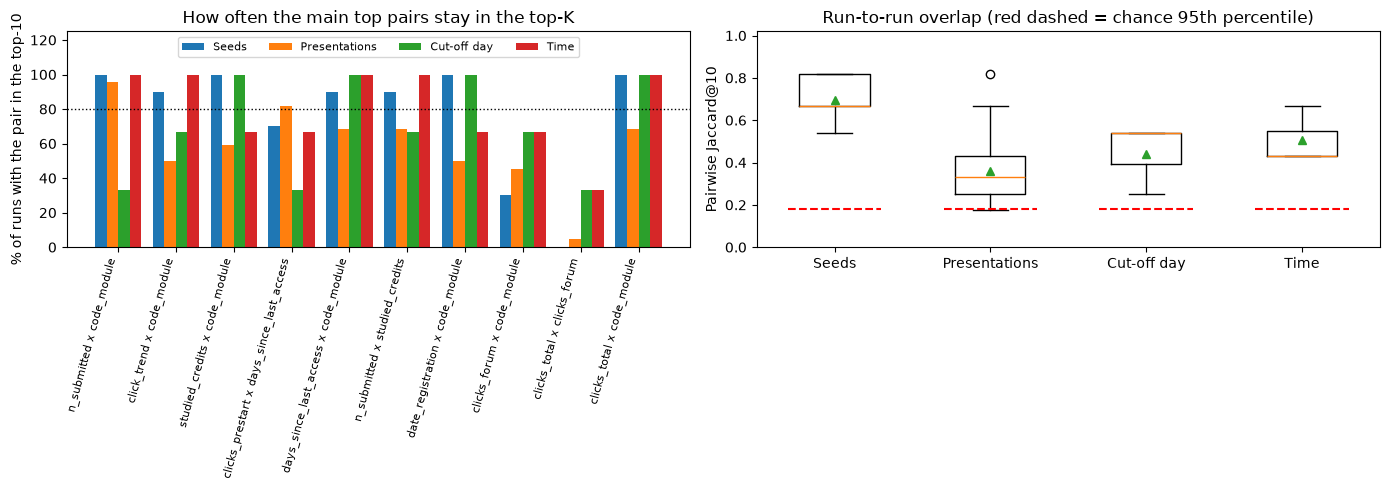

In [20]:
# ---------- Figure 6: stability ----------
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
axes_names = list(PAIRS.keys()); w = 0.8 / len(axes_names); x = np.arange(len(top_pairs))
for i, a in enumerate(axes_names):
    ax[0].bar(x + i * w, share.loc[top_pairs, a] * 100, w, label=a)
ax[0].set_xticks(x + 0.4 - w / 2); ax[0].set_xticklabels(top_pairs, rotation=75, ha="right", fontsize=8); ax[0].set_ylabel(f"% of runs with the pair in the top-{TOP_K}")
ax[0].axhline(CORE_SHARE * 100, color="k", ls=":", lw=1); ax[0].set_ylim(0, 125); ax[0].legend(fontsize=8, ncol=4, loc="upper center"); ax[0].set_title("How often the main top pairs stay in the top-K")
ax[1].boxplot([JAC[a] for a in axes_names], showmeans=True); ax[1].set_xticklabels(axes_names)
for i, a in enumerate(axes_names):
    ax[1].hlines(float(table9.loc[a, "Chance Jaccard (mean / 95th pct)"].split(" / ")[1]), i + 0.7, i + 1.3, colors="red", linestyles="--")
ax[1].set_ylabel(f"Pairwise Jaccard@{TOP_K}"); ax[1].set_ylim(0, 1.02); ax[1].set_title("Run-to-run overlap (red dashed = chance 95th percentile)")
plt.tight_layout(); save_fig("fig6_stability"); plt.show()

## 8. Objective 5 - Demographic fairness (gender, age, deprivation)
The audit uses the LightGBM predictions on the **test students** and the decision threshold chosen from training data.
*Gender and age are not model inputs*, they are only used to split the results; IMD is both an input and an audit group (a sensitivity run without it is included).
For each group: selection rate (share flagged), recall / true-positive rate (dropouts caught), false-positive rate (non-dropouts wrongly flagged), precision and ROC-AUC.
Intervals resample whole students. The *gap* is the largest difference between groups with at least `MIN_POS` dropouts; a permutation test says how often a gap this large appears if group membership were unrelated to the outcome.

In [21]:
thr_lgb = RESULTS["LightGBM"]["thr"]; p_lgb = RESULTS["LightGBM"]["p_test"]
yv, pred = y_test.values, (p_lgb >= thr_lgb).astype(int)
AUDIT = {"gender": test["gender"].values, "age_band": test["age_band"].values, "imd_group": test["imd_group"].values}

def rates(y_, pr_):
    tpr = pr_[y_ == 1].mean() if (y_ == 1).any() else np.nan
    fpr = pr_[y_ == 0].mean() if (y_ == 0).any() else np.nan
    return tpr, fpr

def fairness_table(attr, labels, y_, pr_, p_, draws):
    rows, eligible = [], []
    for g in sorted(set(labels)):
        m = labels == g; n_pos = int((y_[m] == 1).sum())
        tpr, fpr = rates(y_[m], pr_[m])
        t_b = np.array([rates(y_[i[labels[i] == g]], pr_[i[labels[i] == g]])[0] for i in draws]); f_b = np.array([rates(y_[i[labels[i] == g]], pr_[i[labels[i] == g]])[1] for i in draws])
        rows.append({"Attribute": attr, "Group": g, "Students": int(m.sum()), "Dropouts": n_pos, "Dropout rate": y_[m].mean(), "Selection rate": pr_[m].mean(),
                     "Recall (TPR)": tpr, "TPR 95% CI": f"[{np.nanpercentile(t_b, 2.5):.2f}, {np.nanpercentile(t_b, 97.5):.2f}]",
                     "FPR": fpr, "FPR 95% CI": f"[{np.nanpercentile(f_b, 2.5):.2f}, {np.nanpercentile(f_b, 97.5):.2f}]",
                     "Precision": y_[m][pr_[m] == 1].mean() if (pr_[m] == 1).any() else np.nan,
                     "ROC-AUC": roc_auc_score(y_[m], p_[m]) if len(set(y_[m])) == 2 else np.nan,
                     "Reliable (enough dropouts)": "Yes" if n_pos >= MIN_POS else "No - small"})
        if n_pos >= MIN_POS: eligible.append(g)
    return pd.DataFrame(rows), eligible

def gap_stat(labels, eligible, y_, pr_):
    t, f = [], []
    for g in eligible:
        m = labels == g; a, b = rates(y_[m], pr_[m]); t.append(a); f.append(b)
    return np.nanmax(t) - np.nanmin(t), np.nanmax(f) - np.nanmin(f)

fair_tables, gap_rows = [], []
rng = np.random.default_rng(SEED)
for attr, labels in AUDIT.items():
    ft, elig = fairness_table(attr, labels, yv, pred, p_lgb, boot_test.draws); fair_tables.append(ft)
    tg, fg = gap_stat(labels, elig, yv, pred)
    boot_gaps = np.array([max(gap_stat(labels[i], [e for e in elig if (labels[i] == e).any()], yv[i], pred[i])) for i in boot_test.draws[:200]])
    perm = np.array([max(gap_stat(rng.permutation(labels), elig, yv, pred)) for _ in range(500)])
    obs = max(tg, fg)
    gap_rows.append({"Attribute": attr, "Groups compared": ", ".join(elig), "TPR gap": tg, "FPR gap": fg, "Equalised-odds gap": obs,
                     "Gap 95% CI (bootstrap)": f"[{np.percentile(boot_gaps, 2.5):.2f}, {np.percentile(boot_gaps, 97.5):.2f}]",
                     "Permutation p": (perm >= obs).mean(), "Gap larger than chance?": "Yes" if (perm >= obs).mean() < 0.05 else "No"})
table12 = pd.concat(fair_tables, ignore_index=True).set_index(["Attribute", "Group"]); display(table12.round(3)); save_table(table12, "table12_fairness_groups")
table13 = pd.DataFrame(gap_rows).set_index("Attribute"); display(table13.round(3)); save_table(table13, "table13_fairness_gaps")
say("; ".join(f"{a}: equalised-odds gap {table13.loc[a, 'Equalised-odds gap']:.2f} ({'larger than chance' if table13.loc[a, 'Gap larger than chance?'] == 'Yes' else 'could be chance'}, permutation p = {table13.loc[a, 'Permutation p']:.3f})" for a in table13.index)
    + ". Groups with few dropouts are flagged and left out of the gap, because their rates are too noisy to compare.")

Students  Dropouts  Dropout rate  Selection rate  Recall (TPR)    TPR 95% CI    FPR    FPR 95% CI  Precision  ROC-AUC Reliable (enough dropouts)
Attribute Group                                                                                                                                                                     
gender    F                             2426       435         0.179           0.263         0.487  [0.44, 0.53]  0.214  [0.20, 0.23]      0.332    0.708                        Yes
          M                             3086       622         0.202           0.409         0.645  [0.61, 0.68]  0.349  [0.33, 0.37]      0.318    0.704                        Yes
age_band  0-35                          3839       755         0.197           0.378         0.601  [0.57, 0.63]  0.323  [0.31, 0.34]      0.313    0.699                        Yes
          35-55                         1632       294         0.180           0.268         0.524  [0.46, 0.58]  0.212  [0.19, 0.23]      0.352    0.718                        Yes
          55<=                            41         8         0.195           0.293         0.625  [0.13, 1.00]  0.212  [0.09, 0.35]      0.417    0.742                 No - small
imd_group Least deprived (70-100%)      1473       249         0.169           0.274         0.522  [0.46, 0.58]  0.223  [0.20, 0.25]      0.323    0.694                        Yes
          Middle (30-70%)               2118       395         0.186           0.338         0.567  [0.52, 0.62]  0.285  [0.26, 0.31]      0.313    0.712                        Yes
          Most deprived (0-30%)         1713       377         0.220           0.428         0.647  [0.60, 0.70]  0.366  [0.34, 0.39]      0.333    0.698                        Yes
          Unknown                        208        36         0.173           0.236         0.417  [0.25, 0.58]  0.198  [0.14, 0.26]      0.306    0.663                        Yes

,Groups compared,TPR gap,FPR gap,Equalised-odds gap,Gap 95% CI (bootstrap),Permutation p,Gap larger than chance?
Attribute,,,,,,,
gender,"F, M",0.157,0.135,0.157,"[0.13, 0.22]",0.000,Yes
age_band,"0-35, 35-55",0.078,0.111,0.111,"[0.08, 0.15]",0.000,Yes
imd_group,"Least deprived (70-100%), Middle (30-70%), Mos...",0.231,0.168,0.231,"[0.15, 0.41]",0.004,Yes



Interpretation: gender: equalised-odds gap 0.16 (larger than chance, permutation p = 0.000); age_band: equalised-odds gap 0.11 (larger than chance, permutation p = 0.000); imd_group: equalised-odds gap 0.23 (larger than chance, permutation p = 0.004). Groups with few dropouts are flagged and left out of the gap, because their rates are too noisy to compare.


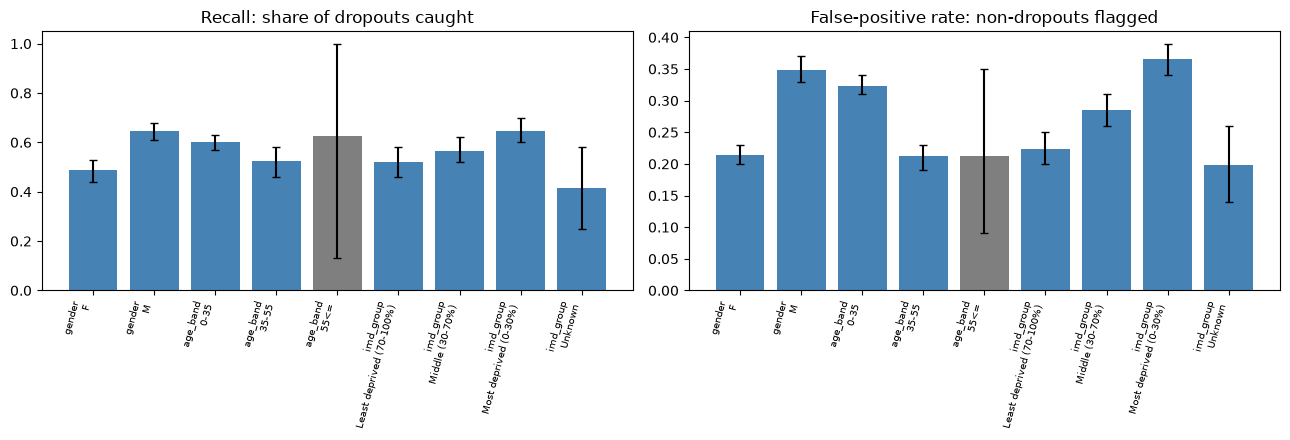

IMD equalised-odds gap with IMD as an input: 0.231 | without IMD: 0.078 | test ROC-AUC without IMD: 0.704 (with: 0.705)

Interpretation: Removing IMD as an input shrinks the IMD gap from 0.23 to 0.08 while AUC is almost unchanged, so the model's direct use of IMD contributes to the disparity. Dropping IMD is therefore a low-cost fairness improvement; any remaining gap comes from other variables (module, credits, prior attempts) that act as proxies.


In [22]:
# ---------- Figure 7: recall and false-positive rate by group ----------
tb = table12.reset_index(); fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
labels_x = [f"{a}\n{g}" for a, g in zip(tb["Attribute"], tb["Group"])]
for k, (col, ci_col, name) in enumerate([("Recall (TPR)", "TPR 95% CI", "Recall: share of dropouts caught"), ("FPR", "FPR 95% CI", "False-positive rate: non-dropouts flagged")]):
    vals = tb[col].values
    lo = np.array([float(s.strip("[]").split(",")[0]) for s in tb[ci_col]]); hi = np.array([float(s.strip("[]").split(",")[1]) for s in tb[ci_col]])
    ax[k].bar(range(len(tb)), vals, yerr=[vals - lo, hi - vals], color=["tab:gray" if r == "No - small" else "steelblue" for r in tb["Reliable (enough dropouts)"]], capsize=3)
    ax[k].set_xticks(range(len(tb))); ax[k].set_xticklabels(labels_x, rotation=75, ha="right", fontsize=7); ax[k].set_title(name)
plt.tight_layout(); save_fig("fig7_fairness"); plt.show()

# ---------- sensitivity: the model without IMD as an input ----------
cols_noimd = [c for c in FEATURES if c != "imd_ord"]
oof_n = get_oof("LightGBM", cols=cols_noimd); pl_n = Platt().fit(oof_n, y_train.values); thr_n = best_f1_threshold(y_train.values, pl_n.transform(oof_n))
m_n = make_model("LightGBM", SEED, spw_of(y_train)).fit(X_train[cols_noimd], y_train)
p_n = pl_n.transform(m_n.predict_proba(X_test[cols_noimd])[:, 1]); pred_n = (p_n >= thr_n).astype(int)
elig_imd = [g for g in sorted(set(AUDIT["imd_group"])) if ((yv == 1) & (AUDIT["imd_group"] == g)).sum() >= MIN_POS]
g_with, g_without = max(gap_stat(AUDIT["imd_group"], elig_imd, yv, pred)), max(gap_stat(AUDIT["imd_group"], elig_imd, yv, pred_n))
print(f"IMD equalised-odds gap with IMD as an input: {g_with:.3f} | without IMD: {g_without:.3f} | test ROC-AUC without IMD: {roc_auc_score(yv, p_n):.3f} (with: {RESULTS['LightGBM']['test']['ROC-AUC']:.3f})")
if g_without < g_with:
    say(f"Removing IMD as an input shrinks the IMD gap from {g_with:.2f} to {g_without:.2f} while AUC is almost unchanged, so the model's direct use of IMD contributes to the disparity. "
        f"Dropping IMD is therefore a low-cost fairness improvement; any remaining gap comes from other variables (module, credits, prior attempts) that act as proxies.")
else:
    say(f"Removing IMD does not shrink the gap ({g_with:.2f} vs {g_without:.2f}), so the disparity does not come from the model reading IMD directly; other variables (module, credits, prior attempts) act as proxies.")

In [23]:
# ---------- is the gender gap just a module effect? compare men and women INSIDE each module ----------
mod_arr, gl = test["code_module"].values, AUDIT["gender"]
rows = []
for mod in sorted(set(mod_arr)):
    f_, m_ = (mod_arr == mod) & (gl == "F"), (mod_arr == mod) & (gl == "M")
    if f_.sum() < 50 or m_.sum() < 50: continue
    tf, ff = rates(yv[f_], pred[f_]); tm, fm = rates(yv[m_], pred[m_])
    rows.append({"Module": mod, "Students": int(f_.sum() + m_.sum()), "Selection gap (M-F)": pred[m_].mean() - pred[f_].mean(), "TPR gap (M-F)": tm - tf, "FPR gap (M-F)": fm - ff})
within = pd.DataFrame(rows).set_index("Module")
w = within["Students"].values
within.loc["Weighted average within modules"] = [w.sum()] + [np.nansum(within[c].values * w) / np.sum(w[~np.isnan(within[c].values)]) for c in within.columns[1:]]
within.loc["Overall (not module-adjusted)"] = [len(yv), pred[gl == "M"].mean() - pred[gl == "F"].mean(),
                                               rates(yv[gl == "M"], pred[gl == "M"])[0] - rates(yv[gl == "F"], pred[gl == "F"])[0],
                                               rates(yv[gl == "M"], pred[gl == "M"])[1] - rates(yv[gl == "F"], pred[gl == "F"])[1]]
display(within.round(3)); save_table(within, "table13b_gender_gap_within_modules")
say(f"Overall, men are flagged {within.loc['Overall (not module-adjusted)', 'Selection gap (M-F)']:+.2f} more often than women; inside the same module the difference is "
    f"{within.loc['Weighted average within modules', 'Selection gap (M-F)']:+.2f}. The part that disappears is a module effect (men and women enrol in different modules, which have different dropout rates); "
    f"what remains is a gender difference the model cannot be blamed for directly, since gender is not an input.")

,Students,Selection gap (M-F),TPR gap (M-F),FPR gap (M-F)
Module,,,,
AAA,158,-0.012,-0.112,0.014
BBB,1239,0.001,-0.093,0.014
CCC,707,0.061,0.111,0.035
DDD,1068,0.046,0.083,0.059
EEE,508,-0.115,-0.019,-0.100
FFF,1350,0.033,-0.038,0.061
GGG,482,0.032,0.000,0.035
Weighted average within modules,5512,0.017,-0.005,0.028
Overall (not module-adjusted),5512,0.145,0.157,0.135



Interpretation: Overall, men are flagged +0.15 more often than women; inside the same module the difference is +0.02. The part that disappears is a module effect (men and women enrol in different modules, which have different dropout rates); what remains is a gender difference the model cannot be blamed for directly, since gender is not an input.


In [24]:
# ---------- are the strongest interactions the same for every group? (explanation fairness) ----------
top3 = list(S_main.sort_values(ascending=False).head(3).index)
lab_s = {"gender": ts["gender"].values, "age_band": ts["age_band"].values, "imd_group": ts["imd_group"].values}
rows = []
for pair in top3:
    a, b = pair.split(" x "); vals = np.abs(pair_values(iv, a, b))
    for attr, lab in lab_s.items():
        for g in sorted(set(lab)):
            m = lab == g
            if m.sum() < 50: continue
            bs = [vals[i[lab[i] == g]].mean() for i in boot_s.draws]
            rows.append({"Pair": pair, "Attribute": attr, "Group": g, "Students (sample)": int(m.sum()), "Mean |interaction|": vals[m].mean(),
                         "95% CI": f"[{np.percentile(bs, 2.5):.3f}, {np.percentile(bs, 97.5):.3f}]"})
table14 = pd.DataFrame(rows).set_index(["Pair", "Attribute", "Group"]); display(table14.round(3)); save_table(table14, "table14_interaction_by_group")

rows = []
for attr, lab in lab_s.items():
    for g in sorted(set(lab)):
        m = lab == g
        if m.sum() < 150: continue
        Sg = pair_strengths(iv[m]); j = jaccard(set(Sg.nlargest(TOP_K).index), set(S_main.nlargest(TOP_K).index))
        rows.append({"Attribute": attr, "Group": g, "Students (sample)": int(m.sum()), f"Jaccard@{TOP_K} with overall ranking": j})
table15 = pd.DataFrame(rows).set_index(["Attribute", "Group"]); display(table15.round(2)); save_table(table15, "table15_ranking_by_group")
say(f"Within each group the top-{TOP_K} pair ranking overlaps with the overall ranking by {table15.iloc[:, -1].min():.2f} to {table15.iloc[:, -1].max():.2f} (Jaccard). "
    f"Where the intervals of a pair overlap between groups, the interaction acts equally strongly for those groups; non-overlapping intervals point to a group-specific effect. "
    f"Small groups have wide intervals and should not be over-read.")

Students (sample)  Mean |interaction|          95% CI
Pair                          Attribute Group                                                                          
n_submitted x code_module     gender    F                                       883               0.088  [0.084, 0.092]
                                        M                                      1117               0.086  [0.081, 0.091]
                              age_band  0-35                                   1378               0.087  [0.083, 0.091]
                                        35-55                                   608               0.086  [0.080, 0.092]
                              imd_group Least deprived (70-100%)                539               0.086  [0.079, 0.093]
                                        Middle (30-70%)                         754               0.088  [0.082, 0.093]
                                        Most deprived (0-30%)                   637               0.088  [0.082, 0.093]
                                        Unknown                                  70               0.074  [0.059, 0.096]
click_trend x code_module     gender    F                                       883               0.035  [0.033, 0.038]
                                        M                                      1117               0.043  [0.040, 0.046]
                              age_band  0-35                                   1378               0.038  [0.036, 0.040]
                                        35-55                                   608               0.043  [0.040, 0.047]
                              imd_group Least deprived (70-100%)                539               0.043  [0.039, 0.046]
                                        Middle (30-70%)                         754               0.038  [0.035, 0.040]
                                        Most deprived (0-30%)                   637               0.038  [0.035, 0.041]
                                        Unknown                                  70               0.055  [0.045, 0.068]
studied_credits x code_module gender    F                                       883               0.043  [0.041, 0.046]
                                        M                                      1117               0.033  [0.030, 0.035]
                              age_band  0-35                                   1378               0.036  [0.034, 0.038]
                                        35-55                                   608               0.042  [0.038, 0.045]
                              imd_group Least deprived (70-100%)                539               0.038  [0.035, 0.042]
                                        Middle (30-70%)                         754               0.037  [0.033, 0.039]
                                        Most deprived (0-30%)                   637               0.040  [0.036, 0.043]
                                        Unknown                                  70               0.020  [0.015, 0.025]

Students (sample)  Jaccard@10 with overall ranking
Attribute Group                                                                       
gender    F                                       883                             0.82
          M                                      1117                             1.00
age_band  0-35                                   1378                             1.00
          35-55                                   608                             1.00
imd_group Least deprived (70-100%)                539                             0.82
          Middle (30-70%)                         754                             1.00
          Most deprived (0-30%)                   637                             0.67


Interpretation: Within each group the top-10 pair ranking overlaps with the overall ranking by 0.67 to 1.00 (Jaccard). Where the intervals of a pair overlap between groups, the interaction acts equally strongly for those groups; non-overlapping intervals point to a group-specific effect. Small groups have wide intervals and should not be over-read.


## 9. Sensitivity: why the AUC here is lower than in many published results
Three set-up choices change the AUC a lot. The same LightGBM (5-fold grouped CV) is run for every combination, so the effect of each choice can be read from the table.

In [25]:
base28 = feat[feat["cutoff"] == MAIN_CUTOFF].copy()
reg_ok = (base28["date_unregistration"].isna() | (base28["date_unregistration"] > MAIN_CUTOFF)) & (base28["date_registration"].isna() | (base28["date_registration"] <= MAIN_CUTOFF))
legacy = base28[["legacy_total_clicks", "legacy_active_days", "legacy_n_types"]].fillna(0).copy()
legacy["legacy_avg_clicks"] = (legacy["legacy_total_clicks"] / legacy["legacy_active_days"].replace(0, np.nan)).fillna(0)
LEG = pd.concat([legacy, pd.get_dummies(base28[["gender", "age_band", "highest_education", "disability"]], drop_first=True, dtype=int)], axis=1)

def cv_auc(rows_mask, drop_fail, feature_set):
    d = base28[rows_mask]
    if drop_fail: d = d[d["final_result"] != "Fail"]
    y = (d["final_result"] == "Withdrawn").astype(int).values
    X = LEG.loc[d.index] if feature_set == "Original 8 features" else make_X(d.assign(), FEATURES)
    oof = np.zeros(len(d))
    for tr, va in StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=SEED).split(X, y, groups=d["id_student"].values):
        m = LGBMClassifier(**LGB_PARAMS, scale_pos_weight=spw_of(pd.Series(y[tr])), random_state=SEED, verbose=-1, n_jobs=-1).fit(X.iloc[tr], y[tr])
        oof[va] = m.predict_proba(X.iloc[va])[:, 1]
    return len(d), y.mean(), roc_auc_score(y, oof)

rows = []
for cohort, mask in [("All enrolments (includes students who already left)", pd.Series(True, index=base28.index)), (f"Still registered at day {MAIN_CUTOFF} (this study)", reg_ok)]:
    for drop_fail in [True, False]:
        for fs in ["Original 8 features", "Final features (this study)"]:
            n, rate, auc = cv_auc(mask, drop_fail, fs)
            rows.append({"Cohort": cohort, "Fail": "removed" if drop_fail else "counted as not dropout", "Features": fs, "Students": n, "Dropout rate": rate, "Grouped-CV ROC-AUC": auc})
table16 = pd.DataFrame(rows).set_index(["Cohort", "Fail", "Features"]); display(table16.round(3)); save_table(table16, "table16_sensitivity")
a_all = table16.xs("removed", level="Fail").iloc[0, -1]; a_risk = table16.xs("counted as not dropout", level="Fail").xs("Final features (this study)", level="Features").iloc[-1, -1]
say(f"The same kind of model scores about {a_all:.2f} AUC when students who already left are kept, Fail is removed and only click and demographic features are used, "
    f"but {a_risk:.2f} for the stricter set-up of this study. The higher number mostly measures 'is the student still registered?', not the early warning that is actually needed. "
    f"Reading published AUCs therefore requires checking the cohort, the Fail definition and the window.")

Students  Dropout rate  Grouped-CV ROC-AUC
Cohort                                             Fail                   Features                                                               
All enrolments (includes students who already l... removed                Original 8 features             25541         0.398               0.799
                                                                          Final features (this study)     25541         0.398               0.866
                                                   counted as not dropout Original 8 features             32593         0.312               0.745
                                                                          Final features (this study)     32593         0.312               0.820
Still registered at day 28 (this study)            removed                Original 8 features             20485         0.249               0.671
                                                                          Final features (this study)     20485         0.249               0.757
                                                   counted as not dropout Original 8 features             27522         0.186               0.601
                                                                          Final features (this study)     27522         0.186               0.693


Interpretation: The same kind of model scores about 0.80 AUC when students who already left are kept, Fail is removed and only click and demographic features are used, but 0.69 for the stricter set-up of this study. The higher number mostly measures 'is the student still registered?', not the early warning that is actually needed. Reading published AUCs therefore requires checking the cohort, the Fail definition and the window.


## 10. Objective checklist and key numbers

In [26]:
import json
lg = RESULTS["LightGBM"]["test"]
checklist = pd.DataFrame([
    ["O1", "Three models built and compared on six metrics, with CIs, calibration, curves, ranking",
     f"Best: {ranking.index[0]} (ROC-AUC {RESULTS[ranking.index[0]]['test']['ROC-AUC']:.3f}); models differ by only {max(v['test']['ROC-AUC'] for v in RESULTS.values()) - min(v['test']['ROC-AUC'] for v in RESULTS.values()):.3f} AUC",
     "Moderate discrimination; honest day-28 risk set"],
    ["O2", "First-order SHAP on held-out students, with CIs, directions and local examples",
     f"Top 3: {', '.join(table4.index[:3])}", "SHAP is not causal; module partly reflects course design"],
    ["O3", "SHAP interaction values, pair ranking, added-value test against an additive model",
     f"Top pair: {table6.index[0]}; gain ROC-AUC {table8.loc['ROC-AUC', 'Gain from interactions']:+.4f} (CI {table8.loc['ROC-AUC', '95% CI (student bootstrap)']})", "Interactions are measurable; predictive gain is small"],
    ["O4", "Stability across seeds, presentations, cut-offs and time versus chance",
     "; ".join(f"{a}: J={table9.loc[a, f'Interaction Jaccard@{TOP_K}']:.2f}" for a in table9.index), "Few runs on cut-off and time axes"],
    ["O5", "Fairness by gender, age, IMD with CIs and permutation tests; interactions by group",
     "; ".join(f"{a}: gap {table13.loc[a, 'Equalised-odds gap']:.2f}" for a in table13.index), "Small groups flagged; IMD sensitivity run included"],
], columns=["Objective", "What was delivered", "Key result", "Main caveat"]).set_index("Objective")
display(checklist); save_table(checklist, "table17_objective_checklist")

KEY = {"risk_set": int(len(df)), "dropout_rate": float(df["y"].mean()), "n_all": int(n_all), "n_left_by_28": int(n_unreg_before),
       "share_withdrawn_left_by_28": float((withdrawn_all & (feat_main["date_unregistration"] <= MAIN_CUTOFF)).sum() / withdrawn_all.sum()),
       "train_rows": int(len(train)), "test_rows": int(len(test)), "features": FEATURES, "variables": VARIABLES,
       "test_metrics": {n: RESULTS[n]["test"] for n in MODEL_NAMES}, "thresholds": {n: float(RESULTS[n]["thr"]) for n in MODEL_NAMES},
       "brier": {n: float(RESULTS[n]["brier"]) for n in MODEL_NAMES}, "ece": {n: float(RESULTS[n]["ece"]) for n in MODEL_NAMES},
       "pair_share": float(pair_total / (main_total + pair_total)), "added_value": table8.reset_index().to_dict(orient="records")}
json.dump(KEY, open(OUT_DIR / "tables" / "key_numbers.json", "w"), indent=2, default=float)
print("Saved all tables to", OUT_DIR / "tables", "and figures to", OUT_DIR / "figures")

,What was delivered,Key result,Main caveat
Objective,,,
O1,Three models built and compared on six metrics...,Best: LightGBM (ROC-AUC 0.705); models differ ...,Moderate discrimination; honest day-28 risk set
O2,"First-order SHAP on held-out students, with CI...","Top 3: code_module, studied_credits, n_submitted",SHAP is not causal; module partly reflects cou...
O3,"SHAP interaction values, pair ranking, added-v...",Top pair: n_submitted x code_module; gain ROC-...,Interactions are measurable; predictive gain i...
O4,"Stability across seeds, presentations, cut-off...",Seeds: J=0.69; Presentations: J=0.36; Cut-off ...,Few runs on cut-off and time axes
O5,"Fairness by gender, age, IMD with CIs and perm...",gender: gap 0.16; age_band: gap 0.11; imd_grou...,Small groups flagged; IMD sensitivity run incl...


Saved all tables to outputs\tables and figures to outputs\figures
